# The Mathematics of Gacha Systems
## Probability, pity mechanics, guarantees and expected costs in *Honkai: Star Rail*

**Research question:** How do the probability of obtaining a desired character and the expected cost change as the number of pulls increases, and how much do pity and guarantee mechanics affect these outcomes?

**Scope:** Character Event Warp. The notebook models 5-star characters and 4-star-or-higher guarantees, then compares theoretical calculations with Monte Carlo simulations.

> **Important modelling note:** Officially published base rates and hard-pity limits are distinguished from community-derived or simplified assumptions. The flat 32.4% soft-pity rate used below is an intentionally simplified adaptation of a user-selected Genshin Impact community model. It is not an official Honkai: Star Rail rate curve.


## 1. Data, rules and assumptions

### 1.1 Character Event Warp rules used in this project

| Mechanic | Model value | Status |
|---|---:|---|
| Base 5-star probability | 0.6% | Official base rate |
| Consolidated 5-star probability | 1.6% | Official published rate |
| 5-star hard pity | 90 pulls | Official guarantee |
| Soft pity begins | Pull 74 | Community-observed convention |
| Featured 5-star chance | 50% | Warp rule |
| Featured guarantee after losing 50/50 | Next 5-star is featured | Warp rule |
| Pull cost | 160 Stellar Jade | In-game conversion |
| 4-star-or-higher guarantee | At least one in 10 pulls | Warp rule |

### 1.2 Soft-pity assumption

For a transparent first model, we use:

- Pulls 1–73: 0.6% conditional chance of a 5-star.
- Pulls 74–89: 32.4% conditional chance of a 5-star.
- Pull 90: 100% chance of a 5-star.

This is a deliberately simplified approximation. It does **not** reproduce the official consolidated rate exactly and should not be presented as the exact in-game probability curve. A later sensitivity analysis can compare it with a gradually increasing soft-pity curve.

### 1.3 Four-star modelling assumption

The official guarantee is expressed as **at least one 4-star-or-higher result within 10 pulls**. A 5-star result can also satisfy that condition. To keep the first model tractable, we use a separate 4-star guarantee counter and assume:

- Base 4-star probability: 5.1% (combined character and Light Cone rate supplied for the project).
- If no 4-star-or-higher result has occurred in the previous nine pulls, the next pull is guaranteed to be 4-star-or-higher.
- On a 4-star result, the 4-star pity counter resets.
- A 5-star result also counts as 4-star-or-higher and resets the 4-star counter.

**Limitation:** The exact interaction between 4-star and 5-star guarantees, and the split between 4-star characters and Light Cones, should be checked against the official Warp details before treating this simplified 4-star model as an exact reproduction of the game.

### 1.4 Featured 4-star modelling

The initial model focuses on the probability of receiving **any 4-star-or-higher item**, not a specific featured 4-star. We will not invent a featured 4-star probability without a verified banner-specific rate. This keeps the main results defensible.


In [97]:
# 2. Imports and project settings

import random
import statistics
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

RANDOM_SEED = 42
N_SIMULATIONS = 100_000

random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)

BASE_5_STAR = 0.006
SOFT_PITY_RATE = 0.324
HARD_PITY_5_STAR = 90
SOFT_PITY_START = 74

BASE_4_STAR = 0.051
HARD_PITY_4_STAR = 10

JADE_PER_PULL = 160
USD_PER_PULL_ESTIMATE = None  # Fill in after selecting the package-pricing method.

print("Simulation count:", N_SIMULATIONS)
print("Random seed:", RANDOM_SEED)


Simulation count: 100000
Random seed: 42


## 3. Theoretical Probability Model

This section explains how the probability of receiving a 5-star character changes with each pull. The model considers the pity system, including soft pity and hard pity.

Let \(p_i\) represent the conditional probability of receiving a 5-star character on pull \(i\), assuming that no 5-star character has appeared earlier in the current pity cycle.

The probability of **not** receiving a 5-star character in the first \(n\) pulls is:

$$
P(\text{no 5-star in } n \text{ pulls})
= \prod_{i=1}^{n}(1-p_i)
$$

Therefore, the probability of receiving **at least one** 5-star character within \(n\) pulls is:

$$
P(\text{at least one 5-star})
= 1-\prod_{i=1}^{n}(1-p_i)
$$

The probability of receiving a featured 5-star character requires an additional calculation because it depends on the 50/50 system. If the player loses the 50/50, the next 5-star character is guaranteed to be the featured character.

The simulation below includes this guarantee mechanic and tracks the results separately.

In [98]:

# 3.1 Conditional 5-star probability for each pull

def five_star_probability(pity_count):
    """Return the conditional 5-star probability for the next pull.

    pity_count is the number of consecutive pulls since the previous 5-star.
    Thus pity_count=0 means the next pull is pull 1 of a new pity cycle.
    """
    next_pull = pity_count + 1

    if next_pull >= HARD_PITY_5_STAR:
        return 1.0
    if next_pull >= SOFT_PITY_START:
        return SOFT_PITY_RATE
    return BASE_5_STAR


def probability_any_five_star(number_of_pulls):
    """Theoretical chance of at least one 5-star within n pulls."""
    survival_probability = 1.0
    pity_count = 0

    for _ in range(number_of_pulls):
        p = five_star_probability(pity_count)
        survival_probability *= (1 - p)
        pity_count += 1

        if p == 1.0:
            survival_probability = 0.0
            break

    return 1 - survival_probability


# Check selected pull counts
for pulls in [10, 20, 50, 72, 88, 90]:
    print(f"{pulls:>3} pulls: {probability_any_five_star(pulls):.2%}")


 10 pulls: 5.84%
 20 pulls: 11.34%
 50 pulls: 25.99%
 72 pulls: 35.16%
 88 pulls: 99.82%
 90 pulls: 100.00%


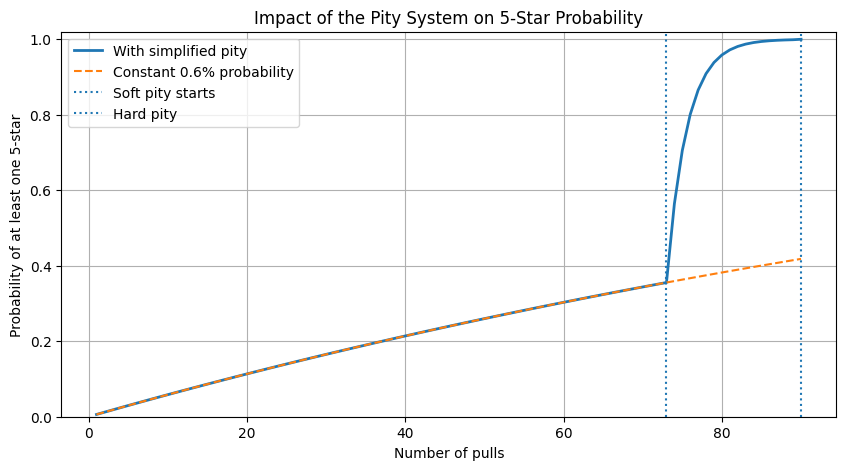

In [99]:
# 3.2 Plot probability of at least one 5-star

pull_counts = range(1, HARD_PITY_5_STAR + 1)

five_star_chances = [
    probability_any_five_star(n) for n in pull_counts
]

constant_chances = [
    probability_constant_rate(n) for n in pull_counts
]

plt.figure(figsize=(10, 5))

plt.plot(
    pull_counts,
    five_star_chances,
    label="With simplified pity",
    linewidth=2
)

plt.plot(
    pull_counts,
    constant_chances,
    label="Constant 0.6% probability",
    linestyle="--"
)

plt.axvline(73, linestyle=":", label="Soft pity starts")
plt.axvline(90, linestyle=":", label="Hard pity")

plt.xlabel("Number of pulls")
plt.ylabel("Probability of at least one 5-star")
plt.title("Impact of the Pity System on 5-Star Probability")

plt.ylim(0, 1.02)
plt.grid(True)
plt.legend()
plt.show()


### 3.3 Comparison: Constant Probability vs. Pity System

To understand the effect of pity mechanics, this project compares two probability models:

- **Constant probability:** Every pull has a fixed 0.6% chance of receiving a 5-star character.
- **Pity system:** The probability increases according to the simplified pity model used in this project. Soft pity begins at pull 74, and hard pity guarantees a 5-star at pull 90.

Let \(p_i\) be the conditional probability of receiving a 5-star on pull \(i\), assuming no 5-star has appeared earlier in the current pity cycle.

The probability of receiving no 5-star in the first \(n\) pulls is:

$$
P(\text{no 5-star in } n \text{ pulls})
= \prod_{i=1}^{n}(1-p_i)
$$

Therefore, the probability of receiving at least one 5-star is:

$$
P(\text{at least one 5-star})
= 1-\prod_{i=1}^{n}(1-p_i)
$$

For the constant probability model, the probability can be calculated using:

$$
P(\text{at least one 5-star})
= 1-(1-0.006)^n
$$

The probability of receiving a featured 5-star is more complicated because it depends on the 50/50 state and the guarantee mechanic. The simulation below tracks that guarantee directly.

In [100]:
# 3.3 Compare Constant Probability vs. Pity System

def probability_constant_rate(number_of_pulls):
    """Calculate the chance of at least one 5-star with a constant 0.6% rate."""
    return 1 - (1 - BASE_5_STAR) ** number_of_pulls


pull_counts = [10, 20, 50, 72, 80, 88, 90]

print("Comparison: Constant Probability vs. Pity System")
print("-" * 55)

for pulls in pull_counts:
    constant = probability_constant_rate(pulls)
    pity = probability_any_five_star(pulls)

    print(
        f"{pulls:3} pulls | "
        f"Constant: {constant:.2%} | "
        f"Pity: {pity:.2%}"
    )

Comparison: Constant Probability vs. Pity System
-------------------------------------------------------
 10 pulls | Constant: 5.84% | Pity: 5.84%
 20 pulls | Constant: 11.34% | Pity: 11.34%
 50 pulls | Constant: 25.99% | Pity: 25.99%
 72 pulls | Constant: 35.16% | Pity: 35.16%
 80 pulls | Constant: 38.21% | Pity: 95.84%
 88 pulls | Constant: 41.12% | Pity: 99.82%
 90 pulls | Constant: 41.82% | Pity: 100.00%


### Interpretation of the Results

The results show that both probability models produce identical results during the first 73 pulls because the probability remains constant at 0.6% per pull.

However, the results begin to differ significantly once soft pity starts at pull 74. Under the simplified pity model, the probability of receiving at least one 5-star increases rapidly.

At 80 pulls, the pity model reaches a probability of 95.84%, compared to only 38.21% under the constant probability model. At 88 pulls, the probability reaches 99.82%. Finally, hard pity guarantees at least one 5-star character by pull 90.

This comparison demonstrates how pity mechanics significantly increase the probability of obtaining a 5-star character compared to a system with a constant probability.

It is important to note that these results describe the probability of receiving any 5-star character, not necessarily the featured character. The 50/50 system and guarantee mechanic are analysed separately.

## 4. Featured 5-Star Character: 50/50 and Guarantee

In the Character Event Warp, obtaining a 5-star character does not always mean receiving the featured character. The outcome depends on the 50/50 system and the guarantee mechanic.

When a 5-star character is obtained, the following rules apply:

1. **Guaranteed featured character:** If the featured guarantee is active, the player receives the featured character.
2. **50/50 system:** If no guarantee is active, there is a 50% chance of receiving the featured character and a 50% chance of receiving a standard 5-star character.
3. **Guarantee after losing:** If the player loses the 50/50, the next 5-star character is guaranteed to be the featured character.
4. **Pity reset:** The 5-star pity counter resets after every 5-star character.

The simulation tracks the pity counter and featured guarantee separately for each simulated player. This makes it possible to analyse not only the probability of receiving a 5-star character, but also the probability of obtaining the featured character.

In [101]:

# 4. Simulate one player's Character Event Warp pulls

def simulate_character_warp(max_pulls, rng=None):
    """Simulate one player's Character Event Warp pulls."""
    if rng is None:
        rng = random

    pity5 = 0
    pity4 = 0
    guaranteed_featured = False

    five_star_count = 0
    featured_count = 0
    four_star_or_higher_count = 0

    first_featured_pull = None
    first_five_star_pull = None

    for pull_number in range(1, max_pulls + 1):
        p5 = five_star_probability(pity5)

        # Check for a 5-star
        if rng.random() < p5:
            five_star_count += 1
            four_star_or_higher_count += 1

            if first_five_star_pull is None:
                first_five_star_pull = pull_number

            if guaranteed_featured:
                is_featured = True
                guaranteed_featured = False
            else:
                is_featured = rng.random() < 0.50
                if not is_featured:
                    guaranteed_featured = True

            if is_featured:
                featured_count += 1
                if first_featured_pull is None:
                    first_featured_pull = pull_number

            pity5 = 0
            pity4 = 0
            continue

        # Check the 4-star-or-higher guarantee
        pity4 += 1

        if pity4 >= HARD_PITY_4_STAR or rng.random() < BASE_4_STAR:
            four_star_or_higher_count += 1
            pity4 = 0

        pity5 += 1

    return {
        "pulls": max_pulls,
        "five_star_count": five_star_count,
        "featured_count": featured_count,
        "four_star_or_higher_count": four_star_or_higher_count,
        "first_five_star_pull": first_five_star_pull,
        "first_featured_pull": first_featured_pull,
        "featured_guarantee_active": guaranteed_featured
    }


# Quick example
simulate_character_warp(72)


{'pulls': 72,
 'five_star_count': 1,
 'featured_count': 1,
 'four_star_or_higher_count': 10,
 'first_five_star_pull': 65,
 'first_featured_pull': 65,
 'featured_guarantee_active': False}

In [102]:
# Test the simulation
test_result = simulate_character_warp(90)

print("Simulation test (90 pulls):")
print("5-star characters:", test_result["five_star_count"])
print("Featured characters:", test_result["featured_count"])
print("4-star-or-higher results:", test_result["four_star_or_higher_count"])

Simulation test (90 pulls):
5-star characters: 1
Featured characters: 1
4-star-or-higher results: 10


## 5. Monte Carlo Simulation

To estimate the probability of obtaining 5-star characters under different saving scenarios, this project uses a Monte Carlo simulation.

The simulation runs 100,000 independent player simulations for each saving scenario:

- **Free-to-play (F2P):** 72 Character Event Warp pulls.
- **Monthly Pass:** 88 Character Event Warp pulls.
- **Monthly Pass + Battle Pass:** 97 Character Event Warp pulls.

These pull totals are based on project-specific reward estimates for Version 4.5. They are not guaranteed monthly income values and may change between game versions.

Standard Passes are excluded because they cannot be used for the limited Character Event Warp.

For each simulated player, the program records the number of 5-star characters and featured characters obtained. The results are then used to estimate the probability of receiving at least one 5-star character and at least one featured character.

In [103]:
# 5.1 Run simulations

SCENARIOS = {
    "F2P": 72,
    "Monthly Pass": 88,
    "Monthly + BP": 97,
}

def run_many_simulations(number_of_players, pulls, seed=RANDOM_SEED):
    rng = random.Random(seed)
    results = [
        simulate_character_warp(pulls, rng)
        for _ in range(number_of_players)
    ]
    return pd.DataFrame(results)


simulation_results = {}
summary_rows = []

for index, (scenario, pulls) in enumerate(SCENARIOS.items()):
    results = run_many_simulations(
        N_SIMULATIONS,
        pulls,
        seed=RANDOM_SEED + index
    )
    simulation_results[scenario] = results

    summary_rows.append({
        "Scenario": scenario,
        "Pulls": pulls,
        "Chance of any 5-star": (results["five_star_count"] > 0).mean(),
        "Chance of featured 5-star": (results["featured_count"] > 0).mean(),
        "Average 5-stars": results["five_star_count"].mean(),
        "Average 4-star-or-higher results": results["four_star_or_higher_count"].mean(),
    })

# Combine the simulation results into one summary table
summary = pd.DataFrame(summary_rows)
summary


,Scenario,Pulls,Chance of any 5-star,Chance of featured 5-star,Average 5-stars,Average 4-star-or-higher results
0,F2P,72,0.35146,0.21124,0.43051,8.88361
1,Monthly Pass,88,0.99799,0.59072,1.20138,11.30360
2,Monthly + BP,97,1.00000,0.62722,1.29481,12.47555


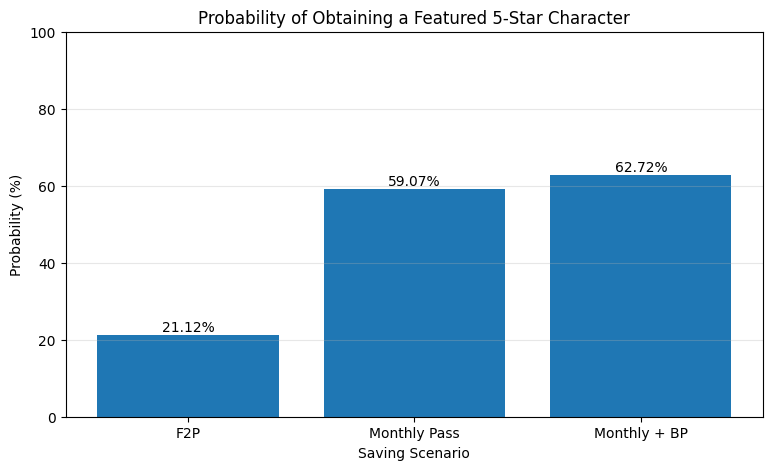

In [104]:
# 5.2 Featured 5-Star Probability Across Saving Scenarios

plt.figure(figsize=(9, 5))

bars = plt.bar(
    summary["Scenario"],
    summary["Chance of featured 5-star"] * 100
)

plt.title("Probability of Obtaining a Featured 5-Star Character")
plt.xlabel("Saving Scenario")
plt.ylabel("Probability (%)")
plt.ylim(0, 100)
plt.grid(axis="y", alpha=0.3)

for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height + 1,
        f"{height:.2f}%",
        ha="center"
    )

plt.show()


### Interpretation of Featured 5-Star Probability

The results show that the probability of obtaining at least one featured 5-star character increases with the number of available pulls.

The F2P scenario, with 72 pulls, has a 21.12% chance of obtaining a featured 5-star character. The Monthly Pass scenario increases this probability to 59.07% with 88 pulls. The Monthly Pass + Battle Pass scenario reaches 62.72% with 97 pulls.

The largest improvement occurs between the F2P and Monthly Pass scenarios. The additional pulls increase the chance of obtaining a featured character considerably.

However, even with 97 pulls, the featured character is not guaranteed. This is because the player can lose the 50/50 when obtaining a 5-star character. The guarantee only applies to the next 5-star character after losing the 50/50.

These results demonstrate that having more pulls significantly improves the chances of obtaining a featured character, but does not always guarantee the desired outcome.

In [105]:
# 5.3 Compare theoretical and simulated chance of any 5-star

comparison_rows = []

for scenario, pulls in SCENARIOS.items():
    theoretical_probability = probability_any_five_star(pulls)

    simulated_probability = (
        simulation_results[scenario]["five_star_count"] > 0
    ).mean()

    comparison_rows.append({
        "Scenario": scenario,
        "Pulls": pulls,
        "Theoretical probability": theoretical_probability,
        "Simulated probability": simulated_probability,
        "Absolute difference": abs(
            theoretical_probability - simulated_probability
        ),
    })

comparison = pd.DataFrame(comparison_rows)
comparison

,Scenario,Pulls,Theoretical probability,Simulated probability,Absolute difference
0,F2P,72,0.351635,0.35146,0.000175
1,Monthly Pass,88,0.998187,0.99799,0.000197
2,Monthly + BP,97,1.000000,1.00000,0.000000


### Interpretation of Theoretical and Simulated Results

The results show a very close agreement between the theoretical probabilities and the Monte Carlo simulation.

For the Free-to-play scenario, the theoretical probability of receiving at least one 5-star character is 35.16%, while the simulated probability is 35.15%.

For the Monthly Pass scenario, the theoretical probability is 99.82%, compared to 99.80% in the simulation.

For the Monthly Pass + Battle Pass scenario, both models reach a probability of 100%. This is because the player has enough pulls to reach the hard pity limit of 90.

The largest absolute difference between the theoretical and simulated results is only 0.000197. This small difference indicates that the simulation produces results that are very close to the mathematical model.

Overall, the comparison supports the reliability of the Monte Carlo simulation for estimating the probability of receiving at least one 5-star character under the assumptions used in this project.

### 5.4 Featured Character Results

The simulation also measures the probability of obtaining at least one featured 5-star character under each saving scenario.

The results show that the probability of obtaining a featured character is considerably lower than the probability of obtaining any 5-star character.

For the Free-to-play scenario, with 72 pulls, the simulated probability of obtaining at least one featured character is 21.12%.

With the Monthly Pass scenario and 88 pulls, this probability increases to 59.07%.

The Monthly Pass + Battle Pass scenario provides 97 pulls and reaches a probability of 62.72%.

Although 97 pulls guarantee at least one 5-star character because of the hard pity system, they do not guarantee that the character will be featured. The 50/50 system and the guarantee mechanic determine the final outcome.

These results demonstrate that obtaining a 5-star character and obtaining the desired featured character are two different outcomes. Even with a relatively high

## 6. Four-Star-or-Higher Guarantee

The simulation includes a simplified four-star-or-higher guarantee mechanic.

The model uses a base probability of 5.1% for receiving a four-star-or-higher result on each pull. If nine consecutive pulls pass without a four-star-or-higher result, the next pull is guaranteed to provide one.

A five-star character also counts as a four-star-or-higher result and resets the guarantee counter.

This section analyses the combined probability of receiving a four-star or five-star result. It does not calculate the probability of obtaining a specific four-star character. A banner-specific featured four-star model would require additional verified rate and guarantee information.


In [106]:
# 6.1 Estimate the chance of at least one 4-star-or-higher result

four_star_rows = []

for scenario, results in simulation_results.items():
    pulls = SCENARIOS[scenario]
    chance = (results["four_star_or_higher_count"] > 0).mean()
    four_star_rows.append({
        "Scenario": scenario,
        "Pulls": pulls,
        "Chance of at least one 4-star-or-higher": chance,
        "Average 4-star-or-higher results": results[
            "four_star_or_higher_count"
        ].mean(),
    })

four_star_summary = pd.DataFrame(four_star_rows)
four_star_summary


,Scenario,Pulls,Chance of at least one 4-star-or-higher,Average 4-star-or-higher results
0,F2P,72,1.0,8.88361
1,Monthly Pass,88,1.0,11.30360
2,Monthly + BP,97,1.0,12.47555


### 6.2 Interpretation of the Results

The simulation shows that all three saving scenarios have a 100% probability of receiving at least one four-star-or-higher result.

This is expected because the simplified model guarantees a four-star-or-higher result if nine consecutive pulls pass without one. Therefore, the guarantee is reached no later than the tenth pull.

The average number of four-star-or-higher results increases with the number of available pulls:

- **F2P (72 pulls):** 8.88 results on average.
- **Monthly Pass (88 pulls):** 11.30 results on average.
- **Monthly Pass + Battle Pass (97 pulls):** 12.48 results on average.

These results demonstrate that additional pulls increase the average number of four-star-or-higher results. However, the probability of receiving at least one such result remains at 100% in all three scenarios.

It is important to remember that this model combines four-star and five-star results. It does not measure the probability of obtaining a specific four-star character.

## 7. Pull Costs and Worst-Case Guarantee

Each Character Event Warp pull costs **160 Stellar Jade**.

The hard pity system creates two important cost limits:

- **One 5-star character:** A 5-star character is guaranteed within 90 pulls, requiring a maximum of 14,400 Stellar Jade.
- **One featured 5-star character:** A featured character is guaranteed within 180 pulls. This assumes the player starts without an active featured guarantee and may first lose the 50/50. The maximum cost is 28,800 Stellar Jade.

The actual USD cost depends on the top-up packages purchased, available first-time purchase bonuses, and the player's existing Stellar Jade balance.

For this reason, USD pricing is analysed separately from the probability model. The exact cost depends on the package-purchase strategy.

In [107]:
# 7.1 Pull and Jade requirements

cost_table = pd.DataFrame([
    {"Goal": "One 5-star (hard pity)", "Pulls": 90},
    {"Goal": "Featured 5-star (worst case)", "Pulls": 180},
    {"Goal": "F2P Version 4.5 scenario", "Pulls": 72},
    {"Goal": "Monthly Pass Version 4.5 scenario", "Pulls": 88},
    {"Goal": "Monthly + BP Version 4.5 scenario", "Pulls": 97},
])

cost_table["Stellar Jade required"] = cost_table["Pulls"] * JADE_PER_PULL
cost_table


,Goal,Pulls,Stellar Jade required
0,One 5-star (hard pity),90,14400
1,Featured 5-star (worst case),180,28800
2,F2P Version 4.5 scenario,72,11520
3,Monthly Pass Version 4.5 scenario,88,14080
4,Monthly + BP Version 4.5 scenario,97,15520


### 7.2 Visual Comparison of Stellar Jade Requirements

The following graph compares the amount of Stellar Jade required for each goal and saving scenario.

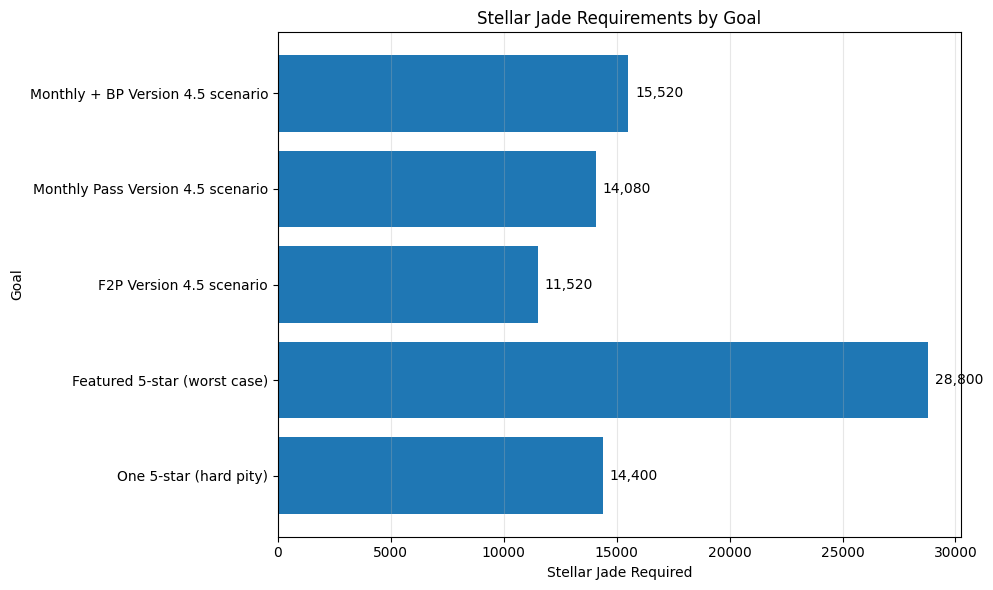

In [108]:
# 7.2 Visual Comparison of Stellar Jade Requirements

plt.figure(figsize=(10, 6))

bars = plt.barh(
    cost_table["Goal"],
    cost_table["Stellar Jade required"]
)

plt.title("Stellar Jade Requirements by Goal")
plt.xlabel("Stellar Jade Required")
plt.ylabel("Goal")
plt.grid(axis="x", alpha=0.3)

for bar in bars:
    width = bar.get_width()
    plt.text(
        width + 300,
        bar.get_y() + bar.get_height() / 2,
        f"{int(width):,}",
        va="center"
    )

plt.tight_layout()
plt.show()


### Interpretation of Stellar Jade Requirements

The results show that the cost of obtaining a featured 5-star character can be significantly higher than the cost of obtaining any 5-star character.

A 5-star character is guaranteed within 90 pulls, requiring a maximum of 14,400 Stellar Jade. However, obtaining a featured 5-star character can require up to 180 pulls, or 28,800 Stellar Jade, if the player starts without an active featured guarantee and loses the first 50/50.

The three saving scenarios provide between 72 and 97 pulls. This means that none of these scenarios can guarantee a featured 5-star character from the starting conditions described above.

The graph also demonstrates how much more expensive the worst-case featured character guarantee is compared with obtaining any 5-star character.

## 8. USD Top-Up Package Analysis

The following package values were transcribed from the user's in-game shop screenshot. They are treated as project input and have not been independently verified against current store prices.

The calculation assumes that 1 Oneiric Shard converts to 1 Stellar Jade and that 160 Stellar Jade are required for one pull.

### Top-Up Package Comparison

| Package | Price (USD) | Base | Bonus | Total |
|:--|:--|--:|--:|--:|
| 1 | 0.99 USD | 60 | 0 | 60 |
| 2 | 4.99 USD | 300 | 30 | 330 |
| 3 | 14.99 USD | 980 | 110 | 1,090 |
| 4 | 29.99 USD | 1,980 | 260 | 2,240 |
| 5 | 49.99 USD | 3,280 | 600 | 3,880 |
| 6 | 99.99 USD | 6,480 | 1,600 | 8,080 |

The next table calculates the effective cost per pull if the entire package value is converted into pulls. Actual purchases are indivisible, so this is a comparison of package efficiency rather than the exact amount a player must spend to reach a particular target.

In [109]:
# 8.1 Package efficiency (USD)

packages = pd.DataFrame([
    {"Price_USD": 0.99, "Base_currency": 60, "Bonus": 0},
    {"Price_USD": 4.99, "Base_currency": 300, "Bonus": 30},
    {"Price_USD": 14.99, "Base_currency": 980, "Bonus": 110},
    {"Price_USD": 29.99, "Base_currency": 1980, "Bonus": 260},
    {"Price_USD": 49.99, "Base_currency": 3280, "Bonus": 600},
    {"Price_USD": 99.99, "Base_currency": 6480, "Bonus": 1600},
])

packages["Total_currency"] = packages["Base_currency"] + packages["Bonus"]
packages["Pull_equivalent"] = packages["Total_currency"] / JADE_PER_PULL
packages["USD_per_pull"] = (
    packages["Price_USD"] / packages["Pull_equivalent"]
)

packages[["Price_USD", "Total_currency", "Pull_equivalent", "USD_per_pull"]]


,Price_USD,Total_currency,Pull_equivalent,USD_per_pull
0,0.99,60,0.3750,2.640000
1,4.99,330,2.0625,2.419394
2,14.99,1090,6.8125,2.200367
3,29.99,2240,14.0000,2.142143
4,49.99,3880,24.2500,2.061443
5,99.99,8080,50.5000,1.980000


### 8.2 Visual Comparison of USD Cost per Pull

The following graph compares the effective cost per pull across the six available top-up packages.

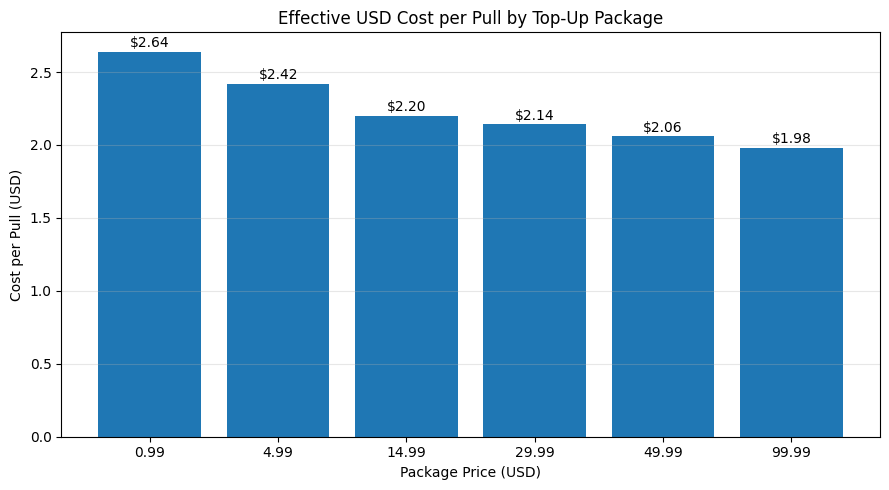

In [110]:
# 8.2 Visual Comparison of USD Cost per Pull

plt.figure(figsize=(9, 5))

bars = plt.bar(
    packages["Price_USD"].astype(str),
    packages["USD_per_pull"]
)

plt.title("Effective USD Cost per Pull by Top-Up Package")
plt.xlabel("Package Price (USD)")
plt.ylabel("Cost per Pull (USD)")
plt.grid(axis="y", alpha=0.3)

for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height + 0.03,
        f"${height:.2f}",
        ha="center"
    )

plt.tight_layout()
plt.show()


### 8.3 Interpretation of Package Efficiency

The largest package has the lowest effective USD cost per pull in the provided screenshot, but it also requires the largest upfront payment.

# The model does not assume that every player should purchase the largest package. An exact-spending model would need to account for the player's current Stellar Jade balance, one-time bonus eligibility, repeat-purchase rules, and possible combinations of different packages.

## 9. Limitations

1. **Simplified soft-pity model:** The soft-pity curve is a simplified, community-derived approximation and does not reproduce the official conditional probability for every pull.

2. **Simplified four-star model:** The four-star-or-higher guarantee is represented using a simplified probability model. It does not reproduce every detail of the game's actual Warp mechanics.

3. **Four-star categories:** The model does not distinguish between four-star characters and four-star Light Cones.

4. **Featured four-star characters:** The simulation does not model the featured four-star lineup or the probability of obtaining a specific four-star character.

5. **Historical reward data:** The Version 4.5 reward scenarios are historical project inputs and should not be interpreted as guaranteed recurring income.

6. **Exact spending:** The package analysis compares effective USD cost per pull, but does not calculate the exact spending required for a particular target. Package combinations, existing Stellar Jade balances, and first-time purchase bonuses would need to be considered.

7. **Simulation assumptions:** Pull outcomes are treated as independent random events, except for the pity counters and guarantee states explicitly tracked by the simulation.

## 10. Conclusion

The results show that the pity system has a major impact on the probability of receiving a 5-star character. Without pity, a constant probability of 0.6% would produce significantly lower success rates. The simplified soft-pity model increases the probability of receiving a 5-star character as the number of pulls increases.

The three saving scenarios produce different results. The Free-to-play (F2P) scenario provides 72 pulls and has a theoretical 35.16% chance of receiving at least one 5-star character. The Monthly Pass scenario provides 88 pulls and increases this probability to approximately 99.82%. The Monthly Pass + Battle Pass scenario provides 97 pulls and reaches 100% under the assumptions of this model.

The 50/50 system adds another layer of uncertainty because receiving a 5-star character does not automatically mean receiving the featured character. However, losing the 50/50 activates a guarantee for the next 5-star character on the Character Event Warp. This means that a featured 5-star character can be guaranteed within a maximum of 180 pulls when starting without an active guarantee.

The Monte Carlo simulation closely matches the theoretical calculations. The largest absolute difference between the theoretical and simulated probabilities is only 0.000197. This indicates that the simulation is consistent with the mathematical model.

However, the model has limitations. The soft-pity probability is a simplified approximation rather than the exact probability curve used by HoYoverse. The four-star mechanics are also simplified. Therefore, the results should be interpreted as an analysis based on the selected assumptions rather than an exact prediction of every in-game outcome.

Overall, this project demonstrates how probability, pity mechanics and guarantees influence the outcomes of a gacha system. It also shows how mathematical calculations and Monte Carlo simulations can be combined to analyse random systems and compare different scenarios.

## 11. Sources

The following sources were used to distinguish official game mechanics, community research and estimated rewards.

### 11.1 Official information

**HoYoverse Help Center – How does the pity system work for different banners and reruns?**

https://support.hoyoverse.com/hc/en-us/articles/50913710696217-How-does-the-pity-system-work-for-different-banners-and-reruns

Used for the official Character Event Warp base probability (0.6%), consolidated probability (1.6%), 90-pull 5-star guarantee and 10-pull 4-star guarantee.

### 11.2 Community-derived information

**Reddit – Everyone is Misunderstanding Soft Pity**

https://www.reddit.com/r/Genshin_Impact/comments/kdy1ky/everyone_is_misunderstanding_soft_pity/?sha

Used as a conceptual reference for understanding soft pity. The probability curve in this project is a simplified modelling assumption adapted from community discussions, not an official Honkai: Star Rail probability formula.

**HoyoBuild – Honkai: Star Rail Pity Calculator**

https://hoyobuild.com/en/hsr/tools/pity-calculator

Used as an additional community reference for the estimated start of soft pity around pull 74. These estimates are unofficial.

### 11.3 Reward data

**Enjoygm – Honkai: Star Rail Version 4.5 Pull Count**

https://www.enjoygm.com/blog/honkai-star-rail/4-5-pulls-count

Used for the estimated Version 4.5 Stellar Jade and Special Pass rewards in the F2P, Monthly Pass and Monthly Pass + Battle Pass scenarios. These values are estimates and depend on the rewards included in the source.

### 11.4 User-collected data

The in-game top-up package prices and bonus amounts were collected manually from the game's purchase screen. The displayed USD prices were used to compare the approximate cost per pull.

### 11.5 Modelling assumptions

The following assumptions were made for this project:

- Base 5-star probability: 0.6%.
- Soft pity starts at pull 74.
- The simplified model uses a 32.4% probability for pulls 74–89.
- Hard pity guarantees a 5-star on pull 90.
- The featured character system is modelled using a 50/50 chance and a guarantee after losing.
- The 4-star system is simplified and is not intended to reproduce every in-game probability detail.

All online sources were accessed on 3 November 2026.